# Question 5: Student Final Examination Marks Estimation
**Task:** Supervised Machine Learning – Multiple Linear Regression  
**Target Variable:** `final_exam_marks` (Continuous, 0 to 100)  
**Input Features Identified:** `attendance`, `internal_assessment`, `assignment_performance`, `study_hours`  

### Marks Rubric (40 Marks):
1. **Section 1: EDA [10 Marks]** — Dataset creation, inspection, and correlation check
2. **Section 2: Technique Implementation [10 Marks]** — Preprocessing & Baseline Linear Regression
3. **Section 3: Evaluate Model [10 Marks]** — MAE, MSE, RMSE, R² Score, and Residual Plot
4. **Section 4: Modify Technique Based on Requirement [10 Marks]** — Ridge Regularization & Random Forest Regressor with Hyperparameter Tuning (GridSearchCV)

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams['figure.figsize'] = (8, 4)
print("Libraries imported successfully!")

Libraries imported successfully!


## Section 1: Exploratory Data Analysis (EDA) [10 Marks]

In [2]:
# 1.1 Simple Exam-Friendly Dataset Generation (500 students)
np.random.seed(42)
n = 500

attendance = np.random.uniform(50, 100, n)               # Percentage
internal_assessment = np.random.uniform(10, 30, n)      # Marks out of 30
assignment_perf = np.random.uniform(8, 20, n)           # Marks out of 20
study_hours = np.random.uniform(2, 25, n)               # Weekly study hours

# Target: Simple linear formula + realistic random noise
final_exam_marks = (
    10.0 
    + 0.25 * attendance 
    + 1.20 * internal_assessment 
    + 0.80 * assignment_perf 
    + 0.60 * study_hours 
    + np.random.normal(0, 3.0, n)
)
final_exam_marks = np.clip(final_exam_marks, 0, 100)

df = pd.DataFrame({
    'attendance': np.round(attendance, 1),
    'internal_assessment': np.round(internal_assessment, 1),
    'assignment_perf': np.round(assignment_perf, 1),
    'study_hours': np.round(study_hours, 1),
    'final_exam_marks': np.round(final_exam_marks, 1)
})

print("Dataset created! Shape:", df.shape)
df.head()

Dataset created! Shape: (500, 5)


,attendance,internal_assessment,assignment_perf,study_hours,final_exam_marks
0,68.7,24.0,10.2,13.9,69.8
1,97.5,20.7,14.5,13.0,76.2
2,86.6,16.2,18.5,2.6,66.7
3,79.9,26.3,16.8,9.8,82.0
4,57.8,23.7,17.7,10.7,76.2


In [3]:
# 1.2 Inspection & Missing Values
print("=== Dataset Info ===")
df.info()
print("\n=== Missing Values ===")
print(df.isnull().sum())
print("\n=== Summary Statistics ===")
display(df.describe().round(2))

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   attendance           500 non-null    float64
 1   internal_assessment  500 non-null    float64
 2   assignment_perf      500 non-null    float64
 3   study_hours          500 non-null    float64
 4   final_exam_marks     500 non-null    float64
dtypes: float64(5)
memory usage: 19.7 KB

=== Missing Values ===
attendance             0
internal_assessment    0
assignment_perf        0
study_hours            0
final_exam_marks       0
dtype: int64

=== Summary Statistics ===


,attendance,internal_assessment,assignment_perf,study_hours,final_exam_marks
count,500.00,500.00,500.00,500.00,500.00
mean,74.93,19.64,14.21,13.42,71.77
std,14.93,5.71,3.56,6.60,9.65
min,50.30,10.10,8.10,2.10,45.10
25%,62.08,14.60,10.90,7.50,64.90
50%,75.65,19.40,14.50,13.70,72.15
75%,87.82,24.52,17.32,19.00,78.95
max,99.60,30.00,20.00,25.00,100.00


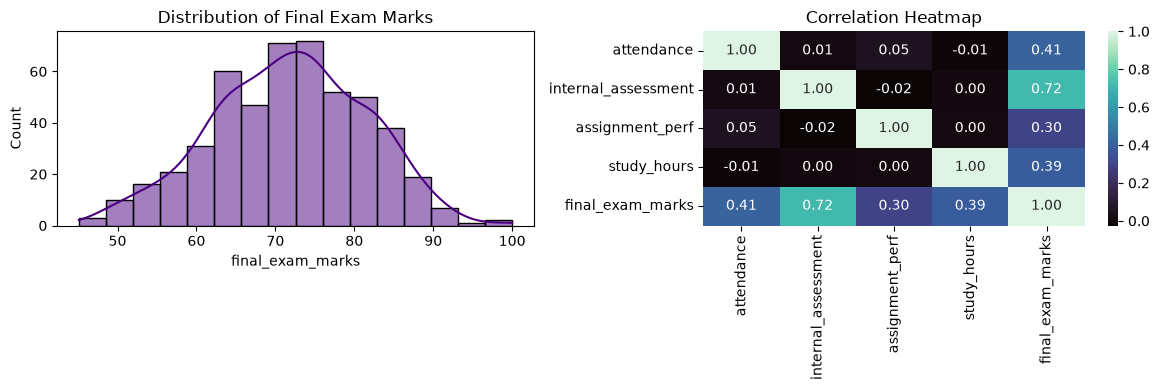

In [4]:
# 1.3 EDA Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['final_exam_marks'], kde=True, ax=axes[0], color='indigo')
axes[0].set_title("Distribution of Final Exam Marks")

sns.heatmap(df.corr(), annot=True, cmap='mako', fmt='.2f', ax=axes[1])
axes[1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## Section 2: Supervised Technique Implementation [10 Marks]

In [5]:
# 2.1 Feature-Target Split and Train-Test Split (80-20)
X = df.drop(columns=['final_exam_marks'])
y = df['final_exam_marks']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (400, 4), X_test: (100, 4)


In [6]:
# 2.2 Baseline Model: Multiple Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
print("Baseline Linear Regression trained!")
print("Intercept:", round(lr.intercept_, 2))
print("Coefficients:", dict(zip(X.columns, np.round(lr.coef_, 2))))

Baseline Linear Regression trained!
Intercept: 71.99
Coefficients: {'attendance': np.float64(3.72), 'internal_assessment': np.float64(7.05), 'assignment_perf': np.float64(2.88), 'study_hours': np.float64(3.74)}


## Section 3: Model Evaluation [10 Marks]

In [7]:
# 3.1 Quantitative Metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

results_lr = {
    'Model': 'Baseline Linear Regression',
    'MAE': round(mae_lr, 2),
    'MSE': round(mse_lr, 2),
    'RMSE': round(rmse_lr, 2),
    'R2 Score': round(r2_lr, 4)
}
display(pd.DataFrame([results_lr]))

,Model,MAE,MSE,RMSE,R2 Score
0,Baseline Linear Regression,2.44,10.6,3.26,0.868


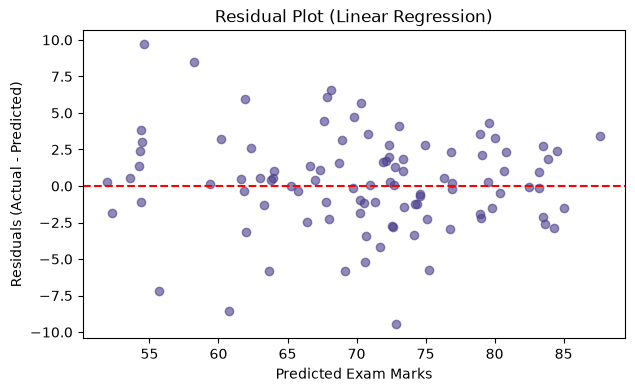

In [8]:
# 3.2 Residual Diagnostic Plot
residuals = y_test - y_pred_lr

plt.figure(figsize=(7, 4))
plt.scatter(y_pred_lr, residuals, color='darkslateblue', alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Exam Marks")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot (Linear Regression)")
plt.show()

## Section 4: Modify Technique Based on Requirement [10 Marks]
**Modifications Applied (from Lab 10):**
1. **Regularization:** Ridge Regression ($L_2$ penalty).
2. **Ensemble Modeling & Hyperparameter Tuning:** `RandomForestRegressor` with `GridSearchCV`.
3. **Feature Importance:** Finding the most impactful academic factor.

In [9]:
# 4.1 Modification A: Ridge Regression (L2 Regularization)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

results_ridge = {
    'Model': 'Ridge Regression (L2)',
    'MAE': round(mean_absolute_error(y_test, y_pred_ridge), 2),
    'MSE': round(mean_squared_error(y_test, y_pred_ridge), 2),
    'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred_ridge)), 2),
    'R2 Score': round(r2_score(y_test, y_pred_ridge), 4)
}

In [10]:
# 4.2 Modification B: Tuned Random Forest Regressor (GridSearchCV)
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 8]
}

grid_rf = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2')
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_

y_pred_rf = best_rf.predict(X_test)

results_rf = {
    'Model': f"Tuned Random Forest {grid_rf.best_params_}",
    'MAE': round(mean_absolute_error(y_test, y_pred_rf), 2),
    'MSE': round(mean_squared_error(y_test, y_pred_rf), 2),
    'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 2),
    'R2 Score': round(r2_score(y_test, y_pred_rf), 4)
}

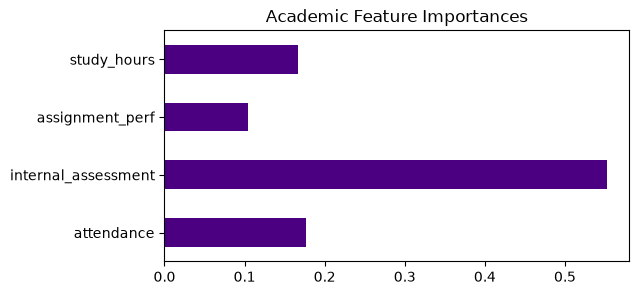

=== Final Model Comparison Table ===


,Model,MAE,MSE,RMSE,R2 Score
0,Baseline Linear Regression,2.44,10.60,3.26,0.8680
1,Ridge Regression (L2),2.44,10.59,3.25,0.8682
2,"Tuned Random Forest {'max_depth': 8, 'n_estima...",2.82,14.21,3.77,0.8230


In [11]:
# 4.3 Feature Importance & Comparison Table
fig, ax = plt.subplots(figsize=(6, 3))
feat_importances = pd.Series(best_rf.feature_importances_, index=X.columns)
feat_importances.plot(kind='barh', color='indigo', ax=ax)
ax.set_title("Academic Feature Importances")
plt.show()

comparison_df = pd.DataFrame([results_lr, results_ridge, results_rf])
print("=== Final Model Comparison Table ===")
display(comparison_df)